# 🟢 ark-gamma-mini-v1 — Text-to-Image

## 🔴 Imports

In [15]:
from pathlib import Path
from datetime import datetime
from contextlib import redirect_stdout
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
import shutil
import sys
import json
import os
import random
import re
import time

## ⚙️ Configuration

In [16]:
MODEL_NAME = "ark-gamma-mini-v1"
ROOT = Path.cwd()

if not (ROOT / "dataset").exists() and (ROOT / "ark-imagine" / "dataset").exists():
    ROOT = ROOT / "ark-imagine"

DATA = ROOT / "dataset" / "Alphabet_VISION_Dataset"
MODEL_LOGS = ROOT / "logs" / MODEL_NAME
MODEL_LOGS.mkdir(parents=True, exist_ok=True)

SELECTED_DATASETS = ["mnist"] # Explicit allowlist
IMAGE_SIZE = 28
BATCH_SIZE = 32
EPOCHS = 10                   # Additional epochs for this run
LR = 1e-3
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
torch.set_num_threads(2)

RUN_ID = datetime.now().strftime("%Y-%m-%d_%H-%M-%S")
RUN_DIR = MODEL_LOGS / RUN_ID
RUN_DIR.mkdir(parents=True, exist_ok=False)

CHECKPOINT_DIR = RUN_DIR / "checkpoints"
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

BEST_PATH = CHECKPOINT_DIR / "best.pt"
LOG_PATH = RUN_DIR / "training.log"
HISTORY_PATH = RUN_DIR / "history.json"
PLOT_PATH = RUN_DIR / "training_plot.png"

print("=" * 68)
print(f"🚀 Model: {MODEL_NAME}")
print(f"📅 Run ID: {RUN_ID}")
print(f"📁 Run directory: {RUN_DIR}")
print(f"🖥️ Device: {DEVICE}")
print(f"🔢 Requested additional epochs: {EPOCHS}")
print(f"📚 Dataset directory: {DATA}")
print("=" * 68)

🚀 Model: ark-gamma-mini-v1
📅 Run ID: 2026-10-19_12-01-11
📁 Run directory: F:\pyvenv\ARK\ark-imagine\logs\ark-gamma-mini-v1\2026-10-19_12-01-11
🖥️ Device: cpu
🔢 Requested additional epochs: 10
📚 Dataset directory: F:\pyvenv\ARK\ark-imagine\dataset\Alphabet_VISION_Dataset


## 🗂️ Dataset — Image/Text Pairs

In [17]:
class PairedDataset(Dataset):
    def __init__(self, split):
        self.items = []
        for name in SELECTED_DATASETS:
            folder = DATA / split / name
            if not folder.is_dir():
                raise FileNotFoundError(f"Dataset folder not found: {folder}")

            for p in sorted(folder.rglob("*")):
                if p.suffix.lower() not in (".png", ".jpg", ".jpeg", ".bmp"):
                    continue

                caption = p.with_suffix(".txt")
                if not caption.is_file():
                    continue

                label = caption.read_text(encoding="utf-8").strip()
                if label not in [str(i) for i in range(10)]:
                    continue  # MNIST v1 vocabulary only

                self.items.append((p, int(label)))

        if not self.items:
            raise ValueError(f"No labeled image pairs found in split={split!r}; datasets={SELECTED_DATASETS}")

    def __len__(self):
        return len(self.items)

    def __getitem__(self, i):
        path, label = self.items[i]
        with Image.open(path) as im:
            im = im.convert("L").resize((IMAGE_SIZE, IMAGE_SIZE))
            arr = np.asarray(im, dtype=np.float32).copy() / 255.0

        image = torch.from_numpy(arr).unsqueeze(0)
        target = torch.tensor(label, dtype=torch.long)
        return image, target


def loaders():
    train_ds = PairedDataset("train")
    valid_ds = PairedDataset("valid")
    train_loader = DataLoader(
        train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0
    )
    valid_loader = DataLoader(
        valid_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0
    )
    return train_loader, valid_loader


train_loader, valid_loader = loaders()
print(f"✅ Training images:   {len(train_loader.dataset):,}")
print(f"✅ Validation images: {len(valid_loader.dataset):,}")
print(f"📦 Training batches:  {len(train_loader)}")
print(f"📦 Validation batches:{len(valid_loader)}")

✅ Training images:   800
✅ Validation images: 200
📦 Training batches:  25
📦 Validation batches:7


## 🧠 Model Architecture — GammaMini CNN

In [18]:
LATENT_DIM = 32
EMBED_DIM = 16
BASE_CHANNELS = 64

class GammaMini(nn.Module):
    def __init__(self):
        super().__init__()

        self.label_embedding = nn.Embedding(10, EMBED_DIM)

        self.fc = nn.Sequential(
            nn.Linear(LATENT_DIM + EMBED_DIM, BASE_CHANNELS * 7 * 7),
            nn.ReLU(inplace=True),
        )

        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(
                BASE_CHANNELS, 32,
                kernel_size=4, stride=2, padding=1
            ),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),

            nn.ConvTranspose2d(
                32, 16,
                kernel_size=4, stride=2, padding=1
            ),
            nn.BatchNorm2d(16),
            nn.ReLU(inplace=True),

            nn.Conv2d(16, 1, kernel_size=3, padding=1),
        )

    def forward(self, y, z=None):
        if z is None:
            z = torch.randn(
                y.size(0), LATENT_DIM,
                device=y.device,
                dtype=self.label_embedding.weight.dtype
            )

        label_features = self.label_embedding(y)
        features = torch.cat([z, label_features], dim=1)

        features = self.fc(features)
        features = features.reshape(-1, BASE_CHANNELS, 7, 7)

        logits = self.decoder(features)

        return logits[:, :, :IMAGE_SIZE, :IMAGE_SIZE]


model = GammaMini().to(DEVICE)

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LR
)

print("=" * 55)
print("🚀 Model: ARK Gamma Mini v1")
print(f"🧠 Model initialized on {DEVICE}")
print(f"🔢 Trainable parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")
print(f"🖼️ Output image size: {IMAGE_SIZE}x{IMAGE_SIZE}")
print("🎨 Output channels: 1 (Grayscale)")
print("🔤 Input vocabulary: 10 digits (0-9)")
print("🏗️ Architecture: Conditional Pixel Decoder")
print("⚙️ Optimizer: Adam")
print(f"📉 Learning rate: {LR}")
print("✅ Model initialization completed successfully.")
print("=" * 55)

🚀 Model: ARK Gamma Mini v1
🧠 Model initialized on cpu
🔢 Trainable parameters: 195,073
🖼️ Output image size: 28x28
🎨 Output channels: 1 (Grayscale)
🔤 Input vocabulary: 10 digits (0-9)
🏗️ Architecture: Conditional Pixel Decoder
⚙️ Optimizer: Adam
📉 Learning rate: 0.001
✅ Model initialization completed successfully.


## 💾 Checkpointing — Save and Resume

In [19]:
def save_checkpoint(
    path, model, opt, epoch, best, history,
    training_start_time, elapsed_training_time
):
    current_elapsed = (
        elapsed_training_time
        + (time.perf_counter() - training_start_time)
    )

    torch.save({
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": opt.state_dict(),
        "epoch": epoch,
        "best_val_loss": best,
        "history": history,
        "selected_datasets": SELECTED_DATASETS,
        "image_size": IMAGE_SIZE,
        "rng_state": torch.get_rng_state(),
        "numpy_rng_state": np.random.get_state(),
        "python_rng_state": random.getstate(),
        "model_name": MODEL_NAME,
        "elapsed_training_time": current_elapsed,
    }, path)

    hours, remainder = divmod(int(current_elapsed), 3600)
    minutes, seconds = divmod(remainder, 60)

    print(f"💾 Checkpoint saved: {path}")
    print(f"   Completed epochs: {epoch}")
    print(f"   Best validation loss: {best:.6f}")
    print(
        f"   Total accumulated training time: "
        f"{hours:02d}:{minutes:02d}:{seconds:02d}"
    )


def resume(path, model, opt):
    path = Path(path)

    if not path.exists():
        print(f"[RESUME] Checkpoint not found: {path}")
        print("[RESUME] Starting training from epoch 1.")
        return 0, float("inf"), [], 0.0

    ck = torch.load(
        path,
        map_location=DEVICE,
        weights_only=False
    )

    saved_state = ck.get("model_state_dict")
    if not isinstance(saved_state, dict):
        print("[RESUME] Invalid checkpoint: model weights not found.")
        print("[RESUME] Starting training from scratch.")
        return 0, float("inf"), [], 0.0

    current_state = model.state_dict()

    saved_keys = set(saved_state.keys())
    current_keys = set(current_state.keys())

    missing_keys = sorted(current_keys - saved_keys)
    unexpected_keys = sorted(saved_keys - current_keys)

    shape_mismatches = sorted(
        key for key in saved_keys & current_keys
        if not isinstance(saved_state[key], torch.Tensor)
        or saved_state[key].shape != current_state[key].shape
    )

    compatible = (
        not missing_keys
        and not unexpected_keys
        and not shape_mismatches
    )

    print("\n[CHECKPOINT] Compatibility report")
    print(f"[CHECKPOINT] File: {path}")
    print(f"[CHECKPOINT] Missing keys: {len(missing_keys)}")
    print(f"[CHECKPOINT] Unexpected keys: {len(unexpected_keys)}")
    print(f"[CHECKPOINT] Shape mismatches: {len(shape_mismatches)}")

    if missing_keys:
        print("[CHECKPOINT] Missing:", missing_keys)

    if unexpected_keys:
        print("[CHECKPOINT] Unexpected:", unexpected_keys)

    for key in shape_mismatches:
        saved_shape = (
            tuple(saved_state[key].shape)
            if isinstance(saved_state[key], torch.Tensor)
            else type(saved_state[key]).__name__
        )
        print(
            f"[CHECKPOINT] Shape mismatch: {key} | "
            f"saved={saved_shape}, "
            f"current={tuple(current_state[key].shape)}"
        )

    if not compatible:
        print(
            "[CHECKPOINT] INCOMPATIBLE architecture. "
            "Model and optimizer states will not be loaded."
        )
        print("[CHECKPOINT] Starting training from scratch.")
        return 0, float("inf"), [], 0.0

    model.load_state_dict(saved_state, strict=True)

    try:
        opt.load_state_dict(ck["optimizer_state_dict"])
    except (KeyError, ValueError, RuntimeError) as exc:
        print(f"[CHECKPOINT] Optimizer state incompatible: {exc}")
        print("[CHECKPOINT] Resetting model and optimizer.")

        model.load_state_dict(current_state, strict=True)

        for group in opt.param_groups:
            group["lr"] = LR
            group["initial_lr"] = LR

        opt.state.clear()

        return 0, float("inf"), [], 0.0

    last_epoch = int(ck.get("epoch", 0))
    best_loss = float(ck.get("best_val_loss", float("inf")))
    history = ck.get("history", [])
    elapsed_training_time = float(
        ck.get("elapsed_training_time", 0.0)
    )

    if "rng_state" in ck:
        torch.set_rng_state(ck["rng_state"].cpu())

    if "numpy_rng_state" in ck:
        np.random.set_state(ck["numpy_rng_state"])

    if "python_rng_state" in ck:
        random.setstate(ck["python_rng_state"])

    if torch.cuda.is_available() and "cuda_rng_state" in ck:
        torch.cuda.set_rng_state_all(ck["cuda_rng_state"])

    print("[CHECKPOINT] Compatible model and optimizer restored.")
    print(f"[RESUME] Last completed epoch: {last_epoch}")
    print(f"[RESUME] Next epoch: {last_epoch + 1}")
    print(f"[RESUME] History entries: {len(history)}")
    print(f"[RESUME] Accumulated training time: "
          f"{elapsed_training_time:.2f} seconds")

    return last_epoch, best_loss, history, elapsed_training_time


previous_checkpoints = sorted(
    MODEL_LOGS.glob("*/checkpoints/best.pt"),
    key=lambda p: p.stat().st_mtime
)

previous_checkpoint = (
    previous_checkpoints[-1]
    if previous_checkpoints
    else None
)

if previous_checkpoint is not None:
    # Keep a best.pt in the current run directory.
    if previous_checkpoint.resolve() != BEST_PATH.resolve():
        shutil.copy2(previous_checkpoint, BEST_PATH)

    resume_path = BEST_PATH
    print(f"🏆 Previous best checkpoint found: {previous_checkpoint}")
    print(f"📦 Current run checkpoint: {BEST_PATH}")
else:
    resume_path = BEST_PATH
    print("[RESUME] No previous best.pt found; starting from scratch.")

start, best, history, elapsed_training_time = resume(
    resume_path,
    model,
    optimizer
)

🏆 Previous best checkpoint found: F:\pyvenv\ARK\ark-imagine\logs\ark-gamma-mini-v1\2026-10-18_15-28-14\checkpoints\best.pt
📦 Current run checkpoint: F:\pyvenv\ARK\ark-imagine\logs\ark-gamma-mini-v1\2026-10-19_12-01-11\checkpoints\best.pt

[CHECKPOINT] Compatibility report
[CHECKPOINT] File: F:\pyvenv\ARK\ark-imagine\logs\ark-gamma-mini-v1\2026-10-19_12-01-11\checkpoints\best.pt
[CHECKPOINT] Missing keys: 0
[CHECKPOINT] Unexpected keys: 0
[CHECKPOINT] Shape mismatches: 0
[CHECKPOINT] Compatible model and optimizer restored.
[RESUME] Last completed epoch: 18
[RESUME] Next epoch: 19
[RESUME] History entries: 18
[RESUME] Accumulated training time: 66.46 seconds


## 🏋️ Training and Validation

In [20]:
class Tee:
    
    def __init__(self, *streams):
        self.streams = streams

    def write(self, message):
        for stream in self.streams:
            stream.write(message)
            stream.flush()

    def flush(self):
        for stream in self.streams:
            stream.flush()


def save_history(history, path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)

    temp_path = path.with_name(path.name + ".tmp")

    with open(temp_path, "w", encoding="utf-8") as f:
        json.dump(
            history,
            f,
            ensure_ascii=False,
            indent=2
        )
        f.flush()
        os.fsync(f.fileno())

    os.replace(temp_path, path)


def plot_history(history, path):
    if not history:
        return

    epochs = [r["epoch"] for r in history]
    train_losses = [r["train_loss"] for r in history]
    valid_losses = [r["valid_loss"] for r in history]

    fig, ax = plt.subplots(figsize=(9, 4.5))
    ax.plot(epochs, train_losses, label="Train loss")
    ax.plot(epochs, valid_losses, label="Validation loss")
    ax.set_title("GammaMini — Training History")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("BCE loss per pixel")
    ax.grid(True, alpha=0.3)
    ax.legend()
    fig.tight_layout()
    fig.savefig(path, dpi=150)
    plt.close(fig)


with open(LOG_PATH, "a", encoding="utf-8") as log_file:
    with redirect_stdout(Tee(sys.stdout, log_file)):
        print("\n🏋️ Starting training...")
        print(f"🧮 Epoch range: {start + 1} to {start + EPOCHS}")

        # Start timing this training session.
        training_start_time = time.perf_counter()

        for epoch in range(start, start + EPOCHS):
            model.train()
            train_sum = 0.0
            train_count = 0

            for x, y in train_loader:
                x, y = x.to(DEVICE), y.to(DEVICE)
                optimizer.zero_grad(set_to_none=True)
                logits = model(y)
                loss = nn.functional.binary_cross_entropy_with_logits(logits, x)
                loss.backward()
                optimizer.step()

                train_sum += loss.item() * x.numel()
                train_count += len(y)

            if train_count == 0:
                raise ValueError("Training dataset is empty.")

            model.eval()
            valid_sum = 0.0
            valid_count = 0

            with torch.no_grad():
                for x, y in valid_loader:
                    x, y = x.to(DEVICE), y.to(DEVICE)
                    logits = model(y)
                    loss = nn.functional.binary_cross_entropy_with_logits(
                        logits, x, reduction="sum"
                    )
                    valid_sum += loss.item()
                    valid_count += len(y)

            if valid_count == 0:
                raise ValueError("Validation dataset is empty.")

            # Normalize both losses per image pixel for a comparable scale.
            train_loss = train_sum / (train_count * IMAGE_SIZE * IMAGE_SIZE)
            valid_loss = valid_sum / (valid_count * IMAGE_SIZE * IMAGE_SIZE)
            
            # Check whether validation loss has improved.
            is_best = valid_loss < best
            
            if is_best:
                best = valid_loss
            
            row = {
                "epoch": epoch + 1,
                "train_loss": train_loss,
                "valid_loss": valid_loss,
            }
            history.append(row)
            
            # Save ONLY best.pt when validation loss improves.
            if is_best:
                save_checkpoint(
                    BEST_PATH,
                    model,
                    optimizer,
                    epoch + 1,
                    best,
                    history,
                    training_start_time,
                    elapsed_training_time
                )
                print(f"🏆 New best checkpoint saved: {BEST_PATH}")
            
            save_history(history, HISTORY_PATH)
            plot_history(history, PLOT_PATH)

            save_history(history, HISTORY_PATH)
            plot_history(history, PLOT_PATH)

            print(
                f"📊 Epoch {epoch + 1}: "
                f"train_loss={train_loss:.6f}, "
                f"valid_loss={valid_loss:.6f}, "
                f"best={best:.6f}"
            )

        # =================================================
        # Final training time summary
        # =================================================

        current_session_time = (
            time.perf_counter() - training_start_time
        )

        total_training_time = (
            elapsed_training_time + current_session_time
        )

        hours, remainder = divmod(
            int(total_training_time), 3600
        )
        minutes, seconds = divmod(remainder, 60)

        session_hours, session_remainder = divmod(
            int(current_session_time), 3600
        )
        session_minutes, session_seconds = divmod(
            session_remainder, 60
        )

        print("\n" + "=" * 68)
        print("✅ Training run completed.")
        print(f"🏆 Best checkpoint: {BEST_PATH}")
        print(f"📄 Training log: {LOG_PATH}")
        print(f"🧾 History JSON: {HISTORY_PATH}")
        print(f"📈 Loss plot: {PLOT_PATH}")
        print(f"🏆 Best validation loss: {best:.6f}")
        
        print(
            f"⏱️ Current session duration: "
            f"{session_hours:02d}:"
            f"{session_minutes:02d}:"
            f"{session_seconds:02d}"
        )
        
        print(
            f"⏱️ Total accumulated training time: "
            f"{hours:02d}:{minutes:02d}:{seconds:02d}"
        )
        
        print("=" * 68)


🏋️ Starting training...
🧮 Epoch range: 19 to 28
📊 Epoch 19: train_loss=0.218493, valid_loss=0.227112, best=0.226571
📊 Epoch 20: train_loss=0.218367, valid_loss=0.227877, best=0.226571
📊 Epoch 21: train_loss=0.218183, valid_loss=0.227231, best=0.226571
📊 Epoch 22: train_loss=0.217168, valid_loss=0.226626, best=0.226571
📊 Epoch 23: train_loss=0.217915, valid_loss=0.226919, best=0.226571
💾 Checkpoint saved: F:\pyvenv\ARK\ark-imagine\logs\ark-gamma-mini-v1\2026-10-19_12-01-11\checkpoints\best.pt
   Completed epochs: 24
   Best validation loss: 0.226530
   Total accumulated training time: 00:01:44
🏆 New best checkpoint saved: F:\pyvenv\ARK\ark-imagine\logs\ark-gamma-mini-v1\2026-10-19_12-01-11\checkpoints\best.pt
📊 Epoch 24: train_loss=0.218162, valid_loss=0.226530, best=0.226530
📊 Epoch 25: train_loss=0.217426, valid_loss=0.226979, best=0.226530
💾 Checkpoint saved: F:\pyvenv\ARK\ark-imagine\logs\ark-gamma-mini-v1\2026-10-19_12-01-11\checkpoints\best.pt
   Completed epochs: 26
   Best vali

## 🔴 Test

🖼️ First image saved to: F:\pyvenv\ARK\ark-imagine\logs\ark-gamma-mini-v1\2026-10-19_12-01-11\generated\digit_4_20261019_120322.png


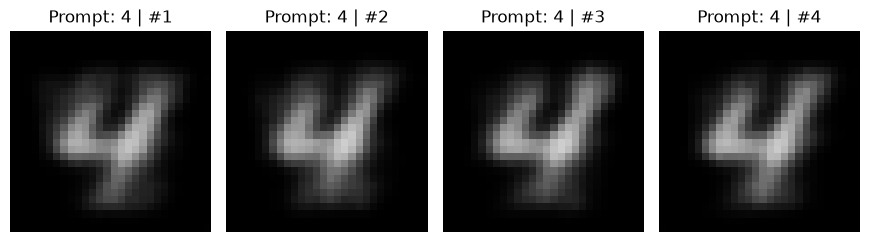

In [21]:
def parse_digit_prompt(prompt):
    text = str(prompt).strip()
    persian_digits = str.maketrans("۰۱۲۳۴۵۶۷۸۹", "0123456789")
    arabic_digits = str.maketrans("٠١٢٣٤٥٦٧٨٩", "0123456789")
    text = text.translate(persian_digits).translate(arabic_digits)
    matches = re.findall(r"(?<!\d)\d(?!\d)", text)
    if not matches:
        raise ValueError("پرامپت باید شامل یک رقم از 0 تا 9 باشد؛ نمونه: 'رقم 7'")
    digit = int(matches[-1])
    if not 0 <= digit <= 9:
        raise ValueError("فقط رقم‌های 0 تا 9 پشتیبانی می‌شوند.")
    return digit


def generate_digit(prompt, num_images=1, save=True):
    if num_images < 1:
        raise ValueError("num_images باید حداقل 1 باشد.")

    digit = parse_digit_prompt(prompt)
    model.eval()

    with torch.no_grad():
        labels = torch.full(
            (num_images,), digit,
            dtype=torch.long,
            device=DEVICE
        )

        z = torch.randn(num_images, LATENT_DIM, device=DEVICE)
        logits = model(labels, z)
        images = torch.sigmoid(logits).cpu().numpy()[:, 0]

    fig, axes = plt.subplots(
        1, num_images,
        figsize=(2.2 * num_images, 2.6),
        squeeze=False
    )

    for i, ax in enumerate(axes[0]):
        ax.imshow(images[i], cmap="gray", vmin=0, vmax=1)
        ax.set_title(f"Prompt: {digit} | #{i + 1}")
        ax.axis("off")

    fig.tight_layout()

    output_path = None

    if save:
        generated_dir = RUN_DIR / "generated"
        generated_dir.mkdir(parents=True, exist_ok=True)

        stamp = datetime.now().strftime("%Y%m%d_%H%M%S")
        output_path = generated_dir / f"digit_{digit}_{stamp}.png"

        plt.imsave(
            output_path,
            images[0],
            cmap="gray",
            vmin=0,
            vmax=1
        )

        print(f"🖼️ First image saved to: {output_path}")

    plt.show()

    return images, output_path


# Change this prompt to any digit prompt, e.g. "رقم 7" or "3".
PROMPT = "4"
generated_images, generated_path = generate_digit(PROMPT, num_images=4, save=True)

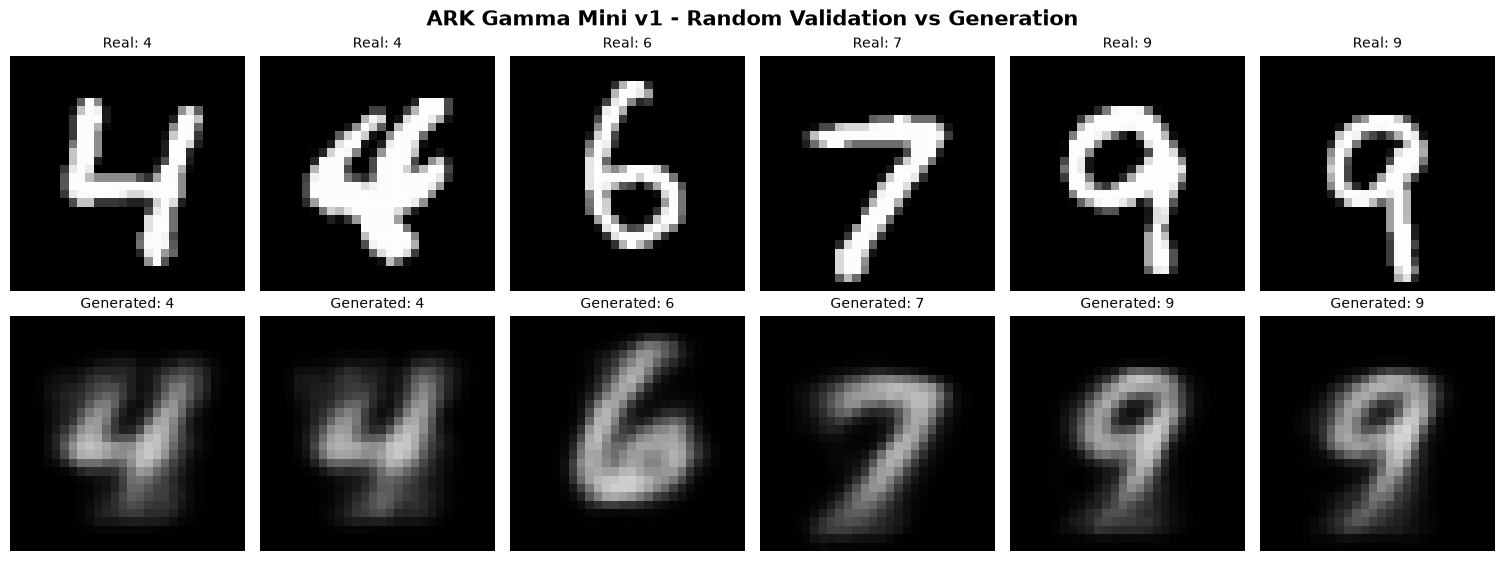

Validation visualization completed.
Total validation samples: 200
Random samples selected: 6
Selected indices: [81, 85, 131, 145, 182, 186]
Model device: cpu


In [22]:
model.eval()

# =========================================================
# Configuration
# =========================================================

NUM_IMAGES = 6

# =========================================================
# Randomly Select Indices from Entire Validation Dataset
# =========================================================

# Works when valid_loader uses a map-style Dataset
dataset_size = len(valid_loader.dataset)
num_images = min(NUM_IMAGES, dataset_size)

# Random indices without replacement
selected_indices = torch.randperm(dataset_size)[:num_images]
selected_indices = selected_indices.sort().values.tolist()

# =========================================================
# Load ONLY Selected Samples
# =========================================================

selected_x = []
selected_y = []

current_index = 0
selected_set = set(selected_indices)

with torch.no_grad():
    for x_batch, y_batch in valid_loader:

        batch_size = len(y_batch)
        batch_end = current_index + batch_size

        # Find selected indices belonging to this batch
        local_indices = [
            idx - current_index
            for idx in selected_indices
            if current_index <= idx < batch_end
        ]

        if local_indices:
            local_indices = torch.tensor(
                local_indices,
                dtype=torch.long
            )

            selected_x.append(x_batch[local_indices])
            selected_y.append(y_batch[local_indices])

        current_index = batch_end

        # Stop once every selected sample has been found
        if current_index > selected_indices[-1]:
            break

# Only the selected images are retained
x_batch = torch.cat(selected_x, dim=0).to(DEVICE)
y_batch = torch.cat(selected_y, dim=0).to(DEVICE)

# =========================================================
# Prepare Real Images and Labels
# =========================================================

real = x_batch.detach().cpu().numpy()[:, 0]
labels = y_batch.detach().cpu().numpy()

# =========================================================
# Generate Images
# =========================================================

with torch.no_grad():

    z = torch.randn(
        num_images,
        LATENT_DIM,
        device=DEVICE
    )

    predicted = torch.sigmoid(
        model(y_batch, z)
    ).detach().cpu().numpy()[:, 0]

# =========================================================
# Visualization
# =========================================================

fig, axes = plt.subplots(
    2,
    num_images,
    figsize=(2.5 * num_images, 5.5),
    squeeze=False,
    layout="constrained"
)

for i in range(num_images):

    axes[0, i].imshow(
        real[i],
        cmap="gray",
        vmin=0,
        vmax=1
    )
    axes[0, i].set_title(
        f"Real: {labels[i]}",
        fontsize=10
    )
    axes[0, i].axis("off")

    axes[1, i].imshow(
        predicted[i],
        cmap="gray",
        vmin=0,
        vmax=1
    )
    axes[1, i].set_title(
        f"Generated: {labels[i]}",
        fontsize=10
    )
    axes[1, i].axis("off")

fig.suptitle(
    "ARK Gamma Mini v1 - Random Validation vs Generation",
    fontsize=15,
    fontweight="bold"
)

plt.show()

print("=" * 55)
print("Validation visualization completed.")
print(f"Total validation samples: {dataset_size}")
print(f"Random samples selected: {num_images}")
print(f"Selected indices: {selected_indices}")
print(f"Model device: {DEVICE}")
print("=" * 55)